<p><img alt="UdeA logo" style="height: 180px !important; width: auto;" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="right" hspace="10px" vspace="0px"></p>


<h1> <b>Laboratorio 04 Regresión lineal y gradiente descendente

Física Computacional II 2026-2</b> </h1>

</div>

<!-- <br> le permite hacer espacios -->
<br>

<hr size=10 noshade color="green">
<p>


<div align="left">       

<h3><i><b>Felipe Quitian Gallego</b><br>  
Universidad de Antioquia <br>
Instituto de Física  <br>
</i></h3>
</div>

# Librerias

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

# Ajuste lineal

In [2]:
# 1. Construimos un DataFrame de pandas con datos lineales simples
np.random.seed(42)
x_data = np.linspace(0, 10, 50)
y_ideal = 2 * x_data
df_ideal = pd.DataFrame({'X': x_data, 'Y': y_ideal})

# 2. Definimos la función que calcula el coste cuadrático (Error Cuadrático Medio)
def funcion_coste(X, Y, theta_0, theta_1):
    m = len(Y)
    predicciones = theta_0 + theta_1 * X
    coste = (1 / (2 * m)) * np.sum((predicciones - Y) ** 2)
    return coste

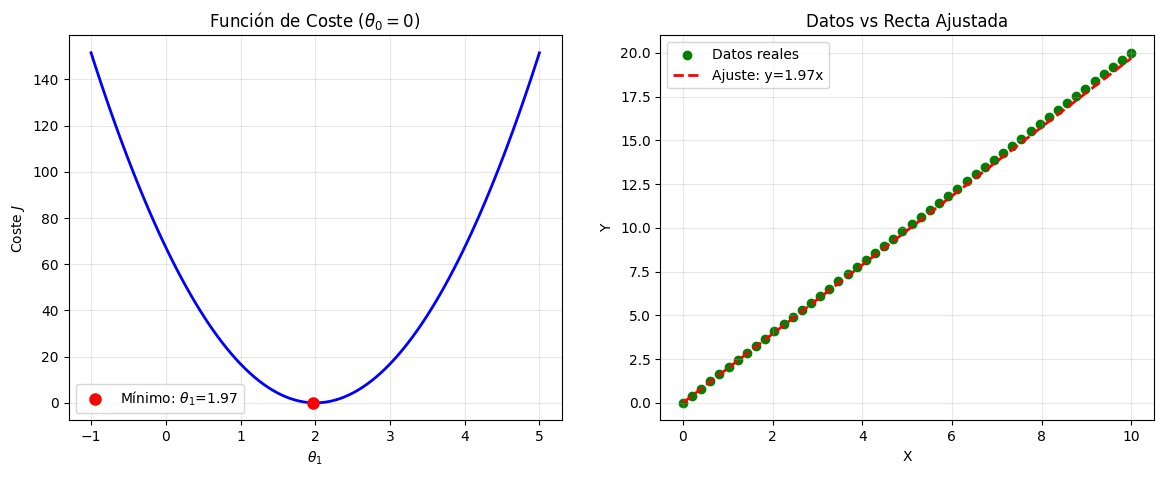

In [3]:
# 3
# Fijamos theta_0 = 0
theta_0_fijo = 0
# Creamos un vector de posibles valores para la pendiente
theta_1_valores = np.linspace(-1, 5, 100)

# Calculamos el coste para cada valor de theta_1
costes_1d = [funcion_coste(df_ideal['X'], df_ideal['Y'], theta_0_fijo, t1) for t1 in theta_1_valores]

# Encontramos el valor que minimiza la función
min_idx = np.argmin(costes_1d)
mejor_theta_1 = theta_1_valores[min_idx]


fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráficamos la función de Coste
ax[0].plot(theta_1_valores, costes_1d, color='blue', linewidth=2)
ax[0].plot(mejor_theta_1, costes_1d[min_idx], 'ro', markersize=8, label=f'Mínimo: $\\theta_1$={mejor_theta_1:.2f}')
ax[0].set_title('Función de Coste ($\\theta_0=0$)')
ax[0].set_xlabel('$\\theta_1$')
ax[0].set_ylabel('Coste $J$')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

# Gráficamos la recta de ajuste sobre los datos con el valor obtenido
ax[1].scatter(df_ideal['X'], df_ideal['Y'], color='green', label='Datos reales')
ax[1].plot(df_ideal['X'], theta_0_fijo + mejor_theta_1 * df_ideal['X'], 'r--', linewidth=2, label=f'Ajuste: y={mejor_theta_1:.2f}x')
ax[1].set_title('Datos vs Recta Ajustada')
ax[1].set_xlabel('X')
ax[1].set_ylabel('Y')
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.show()

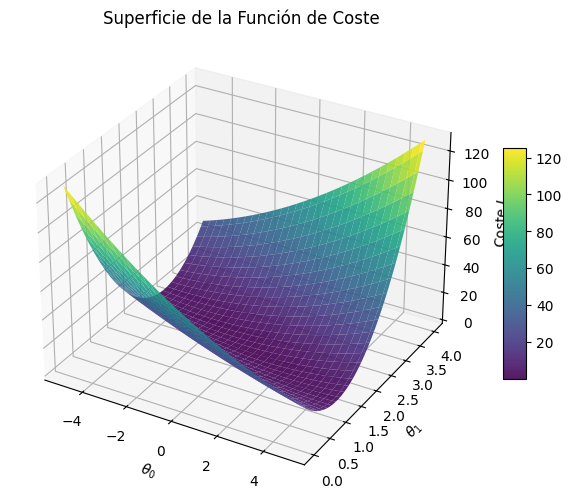

In [4]:
# 4
# Variamos theta_0 y theta_1
theta_0_malla = np.linspace(-5, 5, 60)
theta_1_malla = np.linspace(0, 4, 60)
T0, T1 = np.meshgrid(theta_0_malla, theta_1_malla)
J_malla = np.zeros_like(T0)

# Evaluamos la función de coste en cada combinación de la malla
for i in range(T0.shape[0]):
    for j in range(T0.shape[1]):
        J_malla[i, j] = funcion_coste(df_ideal['X'], df_ideal['Y'], T0[i, j], T1[i, j])

# Gráficamos la Superficie 3D
fig1 = plt.figure(figsize=(8, 6))
ax1 = fig1.add_subplot(111, projection='3d')

surf = ax1.plot_surface(T0, T1, J_malla, cmap='viridis', edgecolor='none', alpha=0.9)
ax1.set_title('Superficie de la Función de Coste')
ax1.set_xlabel('$\\theta_0$')
ax1.set_ylabel('$\\theta_1$')
ax1.set_zlabel('Coste $J$')
fig1.colorbar(surf, ax=ax1, shrink=0.5, aspect=10)

plt.show()

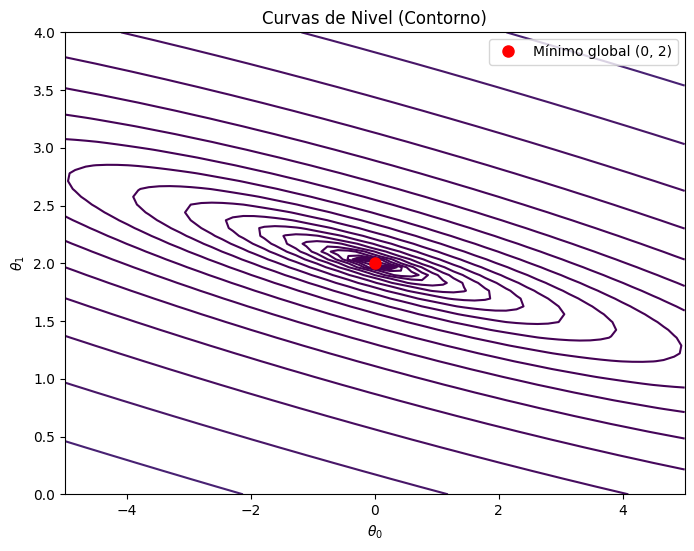

In [5]:
# Gráficomos las Curvas de Nivel
fig2 = plt.figure(figsize=(8, 6))
ax2 = fig2.add_subplot(111)

cp = ax2.contour(T0, T1, J_malla, levels=np.logspace(-2, 3, 25), cmap='viridis')
ax2.plot(0, 2, 'ro', markersize=8, label='Mínimo global (0, 2)')
ax2.set_title('Curvas de Nivel (Contorno)')
ax2.set_xlabel('$\\theta_0$')
ax2.set_ylabel('$\\theta_1$')
ax2.legend()

plt.show()

La función de coste $J(\theta_0, \theta_1)$ es convexa, tiene la forma de un cuenco o paraboloide.

Si hacemos un corte transversal en cualquier dirección, siempre observaremos una parábola. En el plano 2D, las curvas de nivel se manifiestan como elipses concéntricas.

El punto central hacia el que colapsan las elipses y la base del cuenco en 3D representa el mínimo global el cual se encuentra en (0,2). Dado que la función es convexa, carece de mínimos locales, esto garantiza que los algoritmos de optimización, como el gradiente descendente, den la mejor solución posible para $(\theta_0, \theta_1)$.

/tmp/ipykernel_56287/404807685.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend()


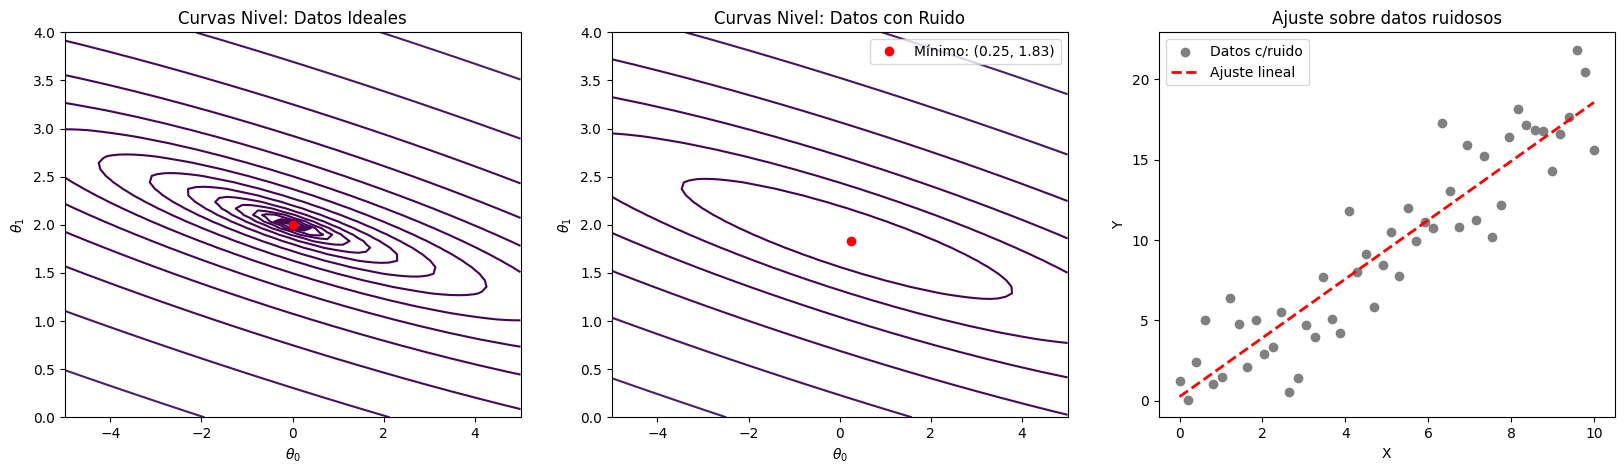

In [6]:
#6
# Generamos un conjunto de datos realista agregando ruido gaussiano
ruido = np.random.normal(0, 2.5, size=len(x_data))
df_ruido = pd.DataFrame({'X': x_data, 'Y': 2 * x_data + ruido})

# Calculamos el coste en la nueva malla con los datos ruidosos
J_malla_ruido = np.zeros_like(T0)
for i in range(T0.shape[0]):
    for j in range(T0.shape[1]):
        J_malla_ruido[i, j] = funcion_coste(df_ruido['X'], df_ruido['Y'], T0[i, j], T1[i, j])

# Localizamos el mínimo empírico en la malla
min_idx_ruido = np.unravel_index(np.argmin(J_malla_ruido, axis=None), J_malla_ruido.shape)
mejor_t0_ruido = T0[min_idx_ruido]
mejor_t1_ruido = T1[min_idx_ruido]

fig, ax = plt.subplots(1, 3, figsize=(20, 5))

# Comparación 1: Contorno Ideal
ax[0].contour(T0, T1, J_malla, levels=np.logspace(-2, 3, 20))
ax[0].plot(0, 2, 'ro', label='Mínimo: (2, 0)')
ax[0].set_title('Curvas Nivel: Datos Ideales')
ax[0].set_xlabel('$\\theta_0$')
ax[0].set_ylabel('$\\theta_1$')
ax[1].legend()

# Comparación 2: Contorno con Ruido
ax[1].contour(T0, T1, J_malla_ruido, levels=np.logspace(-2, 3, 20))
ax[1].plot(mejor_t0_ruido, mejor_t1_ruido, 'ro', label=f'Mínimo: ({mejor_t0_ruido:.2f}, {mejor_t1_ruido:.2f})')
ax[1].set_title('Curvas Nivel: Datos con Ruido')
ax[1].set_xlabel('$\\theta_0$')
ax[1].set_ylabel('$\\theta_1$')
ax[1].legend()

# Comparación 3: Visualización de los datos ruidosos y recta obtenida
ax[2].scatter(df_ruido['X'], df_ruido['Y'], color='grey', label='Datos c/ruido')
ax[2].plot(df_ruido['X'], mejor_t0_ruido + mejor_t1_ruido * df_ruido['X'], 'r--', linewidth=2, label='Ajuste lineal')
ax[2].set_title('Ajuste sobre datos ruidosos')
ax[2].set_xlabel('X')
ax[2].set_ylabel('Y')
ax[2].legend()

plt.show()

En el escenario ideal, el valor mínimo de la función de coste desciende exactamente hasta cero, y su centro se alinea de forma precisa con los parámetros subyacentes $(0, 2)$. Al introducir ruido, la función conserva su forma convexa (elíptica), pero ocurren dos cambios: El mínimo global ya no es cero, porque ninguna recta puede atravesar simultáneamente todos los puntos sin error. El centro de las elipses se desplaza ligeramente desde el ideal $(0, 2)$ para compensar la distribución asimétrica y aleatoria del error en la muestra.

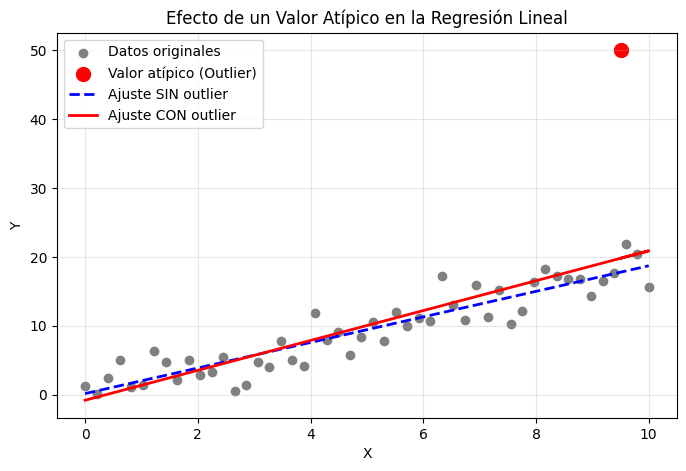

In [7]:
# 7. Análisis de valor atípico
# Usaremos los datos con ruido del punto anterior y agregaremos un valor extremo
x_outlier = np.append(x_data, 9.5)
y_outlier = np.append(2 * x_data + ruido, 50) # Valor atípico muy alejado (Y=50)

# Calculamos el ajuste lineal óptimo
theta_ideal = np.polyfit(x_data, 2 * x_data + ruido, 1)
theta_outlier = np.polyfit(x_outlier, y_outlier, 1)

# Gráfico comparativo
plt.figure(figsize=(8, 5))
plt.scatter(x_outlier[:-1], y_outlier[:-1], color='grey', label='Datos originales')
plt.scatter(x_outlier[-1], y_outlier[-1], color='red', s=100, label='Valor atípico (Outlier)')

# Rectas de ajuste
plt.plot(x_data, theta_ideal[1] + theta_ideal[0] * x_data, 'b--', linewidth=2, label='Ajuste SIN outlier')
plt.plot(x_outlier, theta_outlier[1] + theta_outlier[0] * x_outlier, 'r-', linewidth=2, label='Ajuste CON outlier')

plt.title('Efecto de un Valor Atípico en la Regresión Lineal')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Como se observa en la gráfica, un solo valor atípico extremo es capaz de "arrastrar" significativamente la recta de regresión, alejándola del patrón general que siguen los demás datos.

Al elevar al cuadrado la diferencia entre la predicción y el valor real $(h_\theta(x) - y)^2$, los errores grandes, como el del valor atípico, sufren mucho mas. El algoritmo intenta minimizar esto ajustando toda la recta hacia el outlier, esto muestra que el Error Cuadrático Medio (MSE) es demasiado sensible ante valores atípicos.

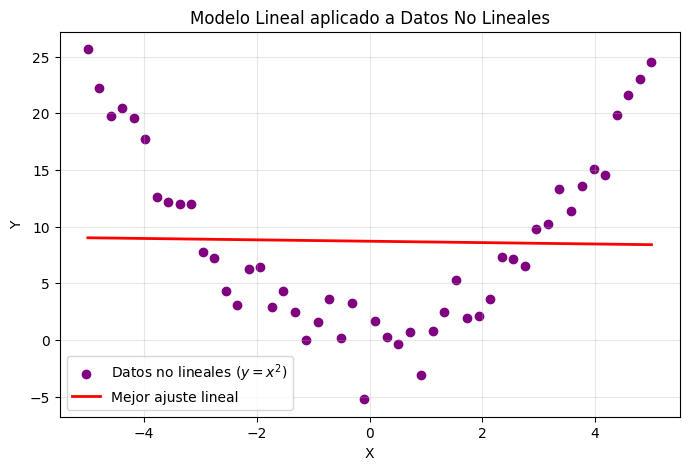

In [8]:
# 8.
# Generamos datos que siguen una forma parabólica
x_nolineal = np.linspace(-5, 5, 50)
y_nolineal = x_nolineal**2 + np.random.normal(0, 2, size=50)

# Ajustamos un modelo estrictamente lineal a estos datos
theta_nolineal = np.polyfit(x_nolineal, y_nolineal, 1)

plt.figure(figsize=(8, 5))
plt.scatter(x_nolineal, y_nolineal, color='purple', label='Datos no lineales ($y=x^2$)')
plt.plot(x_nolineal, theta_nolineal[1] + theta_nolineal[0] * x_nolineal, 'r-', linewidth=2, label='Mejor ajuste lineal')

plt.title('Modelo Lineal aplicado a Datos No Lineales')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Minimizar la función de coste no garantiza que el modelo sea el adecuado para la situación dada.

El algoritmo de regresión lineal siempre encontrará una recta que minimice matemáticamente el error cuadrático respecto a los datos entregados, pero si la naturaleza de los datos es curva, la "mejor recta posible" seguirá arrojando predicciones erradas. El mínimo de la función de coste solo indica el mejor modelo dentro de la familia de modelos elegida (en este caso, rectas), no dice si esa familia es la correcta.

9. Expresión teórica de la función de coste:

Caso con un parámetro ($\theta_1$, asumiendo $\theta_0 = 0$):

La función de coste se reduce a:

$$J(\theta_1) = \frac{1}{2m} \sum_{i=1}^{m} \left( \theta_1 x^{(i)} - y^{(i)} \right)^2$$

Geométricamente, $J(\theta_1)$ es una parábola en 2D. El valor de $\theta_1$ en el punto más bajo de la parábola representa la pendiente para una recta que estamos obligando a pasar estrictamente por el origen $(0,0)$.

Caso con dos parámetros ($\theta_0, \theta_1$):

La expresión teórica completa es:$$J(\theta_0, \theta_1) = \frac{1}{2m} \sum_{i=1}^{m} \left( \theta_0 + \theta_1 x^{(i)} - y^{(i)} \right)^2$$

Geométricamente, $J(\theta_0, \theta_1)$ forma una superficie en 3D similar a un cuenco. El mínimo global que esta en el fondo del cuenco, representa el par de valores exactos (intercepto $\theta_0$ y pendiente $\theta_1$) que definen la recta que pasa lo más cerca posible del centro de masa de todos los datos, minimizando la distancia vertical, osea el error, al cuadrado entre la recta y cada punto de entrenamiento.

# Gradiente descendente

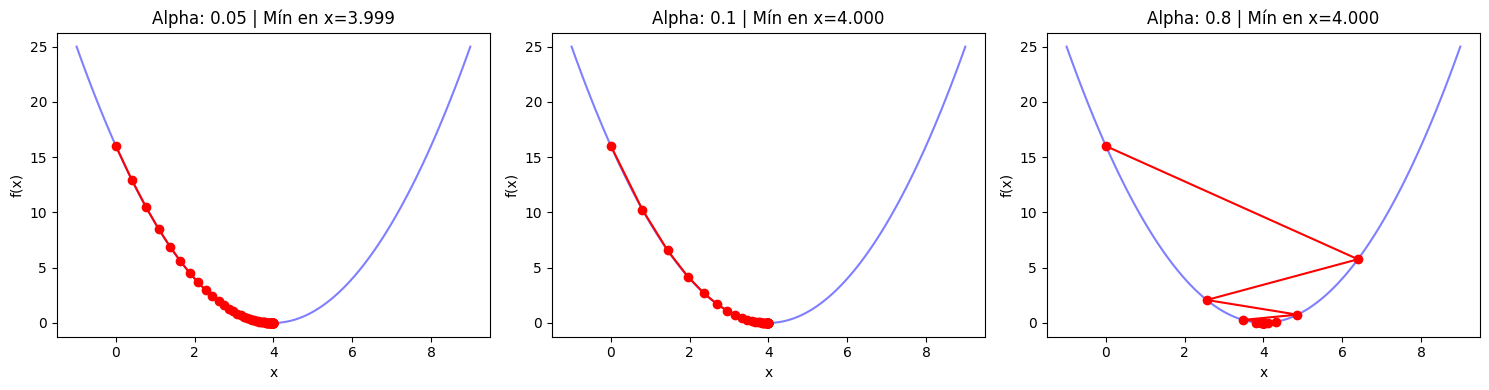

In [9]:
# 10. Definimos nuestro algoritmo de gradiente descendente para f(x) = (x-4)^2
def f(x): return (x - 4)**2
def df(x): return 2 * (x - 4)

def gradiente_descendente_1d(x_ini, alpha, epsilon=1e-4, max_iter=1000):
    x = x_ini
    historial = [x]
    for _ in range(max_iter):
        x_new = x - alpha * df(x)
        if abs(x_new - x) < epsilon:
            break
        x = x_new
        historial.append(x)
    return x, historial

# Probamos con tres alphas diferentes
alphas = [0.05, 0.1, 0.8]
x_inicial = 0.0

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
x_vals = np.linspace(-1, 9, 100)

for i, alpha in enumerate(alphas):
    min_x, hist = gradiente_descendente_1d(x_inicial, alpha)
    ax[i].plot(x_vals, f(x_vals), 'b-', alpha=0.5)
    ax[i].plot(hist, [f(hx) for hx in hist], 'ro-')
    ax[i].set_title(f'Alpha: {alpha} | Mín en x={min_x:.3f}')
    ax[i].set_xlabel('x')
    ax[i].set_ylabel('f(x)')

plt.tight_layout()
plt.show()

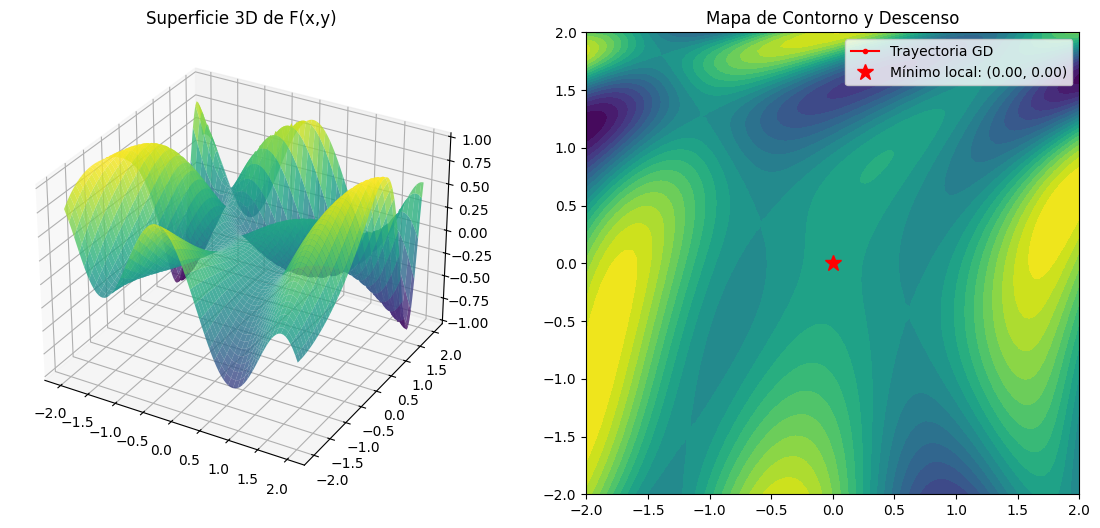

In [10]:
# 11. Definimos función compleja en 2D y su gradiente
def F(x, y):
    u = 0.5 * x**2 - 0.25 * y**2 + 3
    v = 2 * x + 1 - np.exp(y)
    return np.sin(u) * np.cos(v)

def grad_F(x, y):
    u = 0.5 * x**2 - 0.25 * y**2 + 3
    v = 2 * x + 1 - np.exp(y)
    df_dx = x * np.cos(u) * np.cos(v) - 2 * np.sin(u) * np.sin(v)
    df_dy = -0.5 * y * np.cos(u) * np.cos(v) + np.exp(y) * np.sin(u) * np.sin(v)
    return np.array([df_dx, df_dy])

# Malla para visualización
x_m = np.linspace(-2, 2, 100)
y_m = np.linspace(-2, 2, 100)
X_m, Y_m = np.meshgrid(x_m, y_m)
Z_m = F(X_m, Y_m)

# Gradiente descendente en 2D
punto = np.array([0.0, 0.0])
alpha_2d = 0.01
historial_puntos = [punto.copy()]

for _ in range(500):
    grad = grad_F(punto[0], punto[1])
    punto_nuevo = punto - alpha_2d * grad
    if np.linalg.norm(punto_nuevo - punto) < 1e-4:
        break
    punto = punto_nuevo
    historial_puntos.append(punto.copy())

historial_puntos = np.array(historial_puntos)

# Gráficamos
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(X_m, Y_m, Z_m, cmap='viridis', alpha=0.8)
ax1.set_title('Superficie 3D de F(x,y)')

ax2 = fig.add_subplot(122)
cp = ax2.contourf(X_m, Y_m, Z_m, levels=20, cmap='viridis')
ax2.plot(historial_puntos[:, 0], historial_puntos[:, 1], 'r.-', label='Trayectoria GD')
ax2.plot(punto[0], punto[1], 'r*', markersize=12, label=f'Mínimo local: ({punto[0]:.2f}, {punto[1]:.2f})')
ax2.set_title('Mapa de Contorno y Descenso')
ax2.legend()

plt.show()

# Modelo de machine learning:

--- Comparación de Parámetros ---
Manual  -> Intercepto (t0): 0.2090 | Pendiente (t1): 0.2015
Sklearn -> Intercepto (t0): 0.2090 | Pendiente (t1): 0.2015


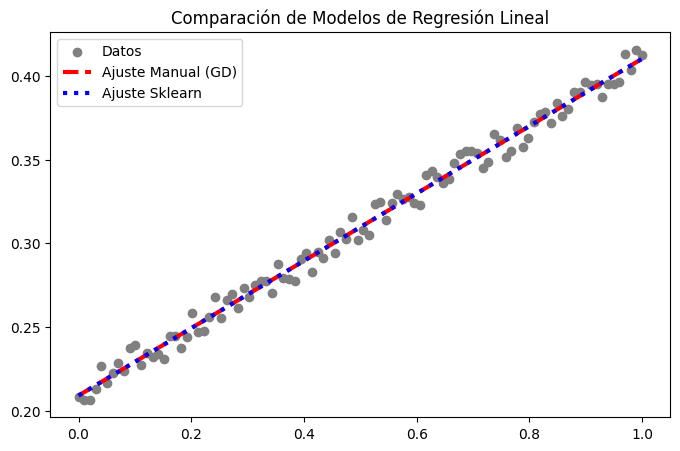

In [11]:
# 12.
# Usamos los datos datos
X = np.linspace(0, 1, 100)
y = 0.2 + 0.2*X + 0.02*np.random.random(100)

# Construimos el algoritmo
def regresion_manual(X, y, alpha=0.5, iteraciones=1000):
    m = len(y)
    theta_0, theta_1 = 0.0, 0.0
    for _ in range(iteraciones):
        prediccion = theta_0 + theta_1 * X
        error = prediccion - y
        # Derivadas parciales de la función de coste
        d_theta_0 = (1/m) * np.sum(error)
        d_theta_1 = (1/m) * np.sum(error * X)

        theta_0 -= alpha * d_theta_0
        theta_1 -= alpha * d_theta_1
    return theta_0, theta_1

t0_manual, t1_manual = regresion_manual(X, y)

# 11b. Comparamos con Sklearn
modelo_sk = LinearRegression()
modelo_sk.fit(X.reshape(-1, 1), y)
t0_sk, t1_sk = modelo_sk.intercept_, modelo_sk.coef_[0]

print("--- Comparación de Parámetros ---")
print(f"Manual  -> Intercepto (t0): {t0_manual:.4f} | Pendiente (t1): {t1_manual:.4f}")
print(f"Sklearn -> Intercepto (t0): {t0_sk:.4f} | Pendiente (t1): {t1_sk:.4f}")

# Gráficamos
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='gray', label='Datos')
plt.plot(X, t0_manual + t1_manual * X, 'r--', lw=3, label='Ajuste Manual (GD)')
plt.plot(X, t0_sk + t1_sk * X, 'b:', lw=3, label='Ajuste Sklearn')
plt.legend()
plt.title('Comparación de Modelos de Regresión Lineal')
plt.show()

# Analisis y concluciones

## A) Hallazgos Descriptivos

La implementación de la regresión lineal utilizando la función de coste del Error Cuadrático Medio y el algoritmo de gradiente descendente permitió validar los fundamentos teóricos del modelo. Fue notable la convergencia lograda en la optimización de los parámetros $\theta_0$ y $\theta_1$. Al fijar inicialmente $\theta_0=0$, el modelo convergió rápidamente hacia el valor óptimo de $\theta_1=2$, lo cual era predecible dado el diseño del conjunto de datos ($Y = 2X$). Esto demuestra la eficacia del gradiente descendente para encontrar el mínimo global en espacios de parámetros de baja dimensionalidad cuando la función de coste es estrictamente convexa. Sin embargo, se encontro vulnerabilidades en el uso de la función de coste cuadrática (MSE). La introducción de un solo valor atípico alteró la la recta de ajuste, demostrando una alta sensibilidad a valores anómalos. La penalización cuadrática fuerza al algoritmo a minimizar el error, resultando en un ajuste sesgado que ya no representa fielmente la tendencia principal de los datos. Aunque la minimización de la función de coste garantiza encontrar los mejores parámetros para ese modelo y esos datos específicos, no confiere inmunidad frente a datos atípicos. Finalmente, la evaluación del modelo lineal sobre datos de naturaleza parabólica ($Y = X^2$) evidenció el problema del subajuste (underfitting). Aunque el algoritmo logró converger al mínimo de su función de coste para encontrar la "mejor recta", el desempeño predictivo fue deficiente. Este resultado confirma que el éxito de la optimización no exime la responsabilidad inicial de seleccionar un modelo adecuado que capture la estructura de los datos.

## B) Patrones visuales

Las representaciones gráficas de la función de coste proporcionaron una comprensión espacial del proceso de optimización. La superficie 3D de $J(\theta_0, \theta_1)$ exhibió la característica forma de paraboloide convexo, confirmando la existencia de un único mínimo global hacia el cual el gradiente descendente puede converger sin quedar atrapado en mínimos locales. Los mapas de contorno (curvas de nivel) resultaron reveladores al analizar el impacto del ruido en los datos. En el escenario con datos ideales ($Y=2X$), el mínimo de las elipses concéntricas es correctamente en coordenadas (0,2), con un valor de coste cero. En contraste, en el escenario con ruido gaussiano, se observó un patrón geométrico similar, pero el centro de las curvas de nivel se desplazó ligeramente y el coste mínimo ya no fue cero. La regularidad de estas curvas confirma que la función de coste es suave y diferenciable, características ideales para el uso del gradiente descendente.